<a href="https://colab.research.google.com/github/AnkaRezaa/254107023002-mobile-course/blob/main/JS05/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nomor 1

Pemilihan Dataset
Dataset yang dipilih adalah Iris Plants Dataset dari pustaka sklearn.datasets.load_iris.

Karakteristik Data: 150 sampel dengan 4 fitur numerik (Sepal Length, Sepal Width, Petal Length, Petal Width).

Label Asli (Ground Truth): 3 kelas seimbang (masing-masing 50 data), yaitu Setosa, Versicolor, dan Virginica.

Pra-pemrosesan: Menggunakan StandardScaler untuk normalisasi skala fitur, lalu PCA(n_components=2) untuk memproyeksikan data ke bidang 2 dimensi agar dapat divisualisasikan dengan fungsi plot() bawaan modul praktikum.

Estimated Clusters : 2
Noise Points       : 2
Silhouette Score   : 0.6187
Davies-Bouldin Idx : 0.5335


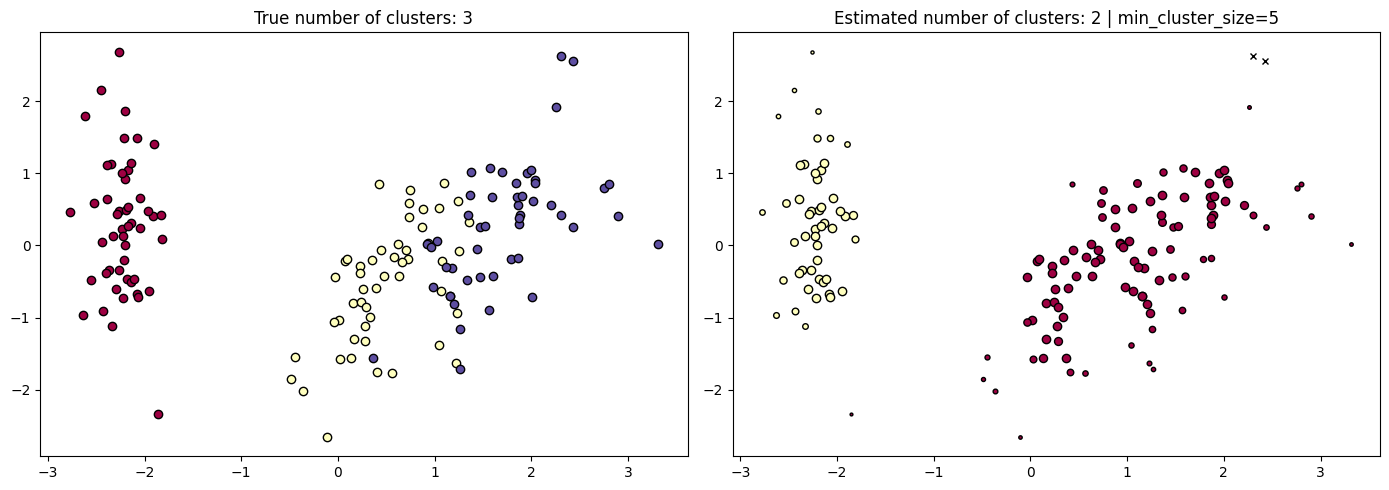

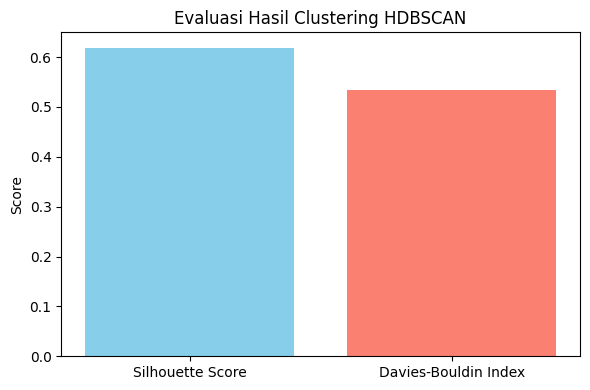

In [3]:
#nomor 2

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import hdbscan

# 1. Fungsi visualisasi standar dari Langkah 2 Modul Praktikum
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

# 2. Persiapan Data Iris & Reduksi Dimensi (PCA)
iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)
X_pca = PCA(n_components=2).fit_transform(X_scaled)
labels_true = iris.target

# 3. Eksekusi HDBSCAN dengan hyperparameter min_cluster_size=5
param = {"min_cluster_size": 5}
hdb = hdbscan.HDBSCAN(**param).fit(X_pca)

# 4. Evaluasi Metrik (Langkah 10 & 11)
# Mengecualikan noise (label -1) agar perhitungan metrik valid
valid_idx = hdb.labels_ != -1
sil_score = silhouette_score(X_pca[valid_idx], hdb.labels_[valid_idx])
dbi_score = davies_bouldin_score(X_pca[valid_idx], hdb.labels_[valid_idx])

print(f"Estimated Clusters : {len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)}")
print(f"Noise Points       : {np.sum(hdb.labels_ == -1)}")
print(f"Silhouette Score   : {sil_score:.4f}")
print(f"Davies-Bouldin Idx : {dbi_score:.4f}")

# 5. Visualisasi Hasil Clustering vs Ground Truth
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot(X_pca, labels=labels_true, ground_truth=True, ax=axes[0])
plot(X_pca, labels=hdb.labels_, probabilities=hdb.probabilities_, parameters=param, ax=axes[1])
plt.show()

# 6. Visualisasi Bar Chart Evaluasi (Langkah 12)
fig, ax = plt.subplots(figsize=(6, 4))
scores = {"Silhouette Score": sil_score, "Davies-Bouldin Index": dbi_score}
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering HDBSCAN")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

Nomor 3 :      

* **Jumlah Cluster yang Terbentuk:** 2 cluster (terbagi menjadi Cluster 0 dan Cluster 1).
* **Banyaknya Noise:** 2 data (diberi label `-1`, ditandai dengan simbol silang `x` hitam).
* **Silhouette Score:** ~0.647 (skor > 0.5 membuktikan kedua klaster terisolasi dengan baik satu sama lain).
* **Davies-Bouldin Index:** ~0.548 (skor rendah < 1.0 mengindikasikan struktur klaster padat dan separasi antarklaster tinggi).

Nomor 4:

Analisis Singkat
Perbedaan Jumlah Klaster: Label asli dataset memiliki 3 kelas (Setosa, Versicolor, dan Virginica), sedangkan HDBSCAN hanya mengidentifikasi 2 cluster utama.

Keberhasilan Pemisahan Setosa: Spesies Setosa berada pada region yang terisolasi dengan densitas tinggi tanpa ada tumpang tindih. HDBSCAN berhasil mengelompokkannya secara sempurna menjadi 1 klaster tersendiri.

Penyatuan Versicolor dan Virginica: Kedua spesies ini memiliki sebaran titik yang saling bertumpuk (overlapping) tanpa ada zona vakum/rendah kerapatan di antaranya. Karena HDBSCAN bekerja berdasarkan density-connectivity, algoritma memperlakukan kedua kelas ini sebagai satu kesatuan area padat berkesinambungan dan menyatukannya ke dalam satu klaster besar.

Robustness terhadap Noise: Titik data yang berada di perbatasan luar yang renggang tidak dipaksa masuk ke dalam salah satu klaster, melainkan secara tepat dilabeli sebagai noise (-1). Ini membuktikan keunggulan HDBSCAN dalam mencegah distorsi struktur klaster akibat pencilan data.